<a href="https://colab.research.google.com/github/Carlsonjacob2004/EO_IR_Capstone/blob/main/notebooks/01_prepare_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: Mount Drive and list the raw folder

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, shutil, subprocess, zipfile
from collections import Counter
DRIVE_ROOT = "/content/drive/MyDrive/EO_IR_Capstone"
RAW_DIR  = f"{DRIVE_ROOT}/data/raw"
PREP_DIR = f"{DRIVE_ROOT}/data/prepared"
print(os.listdir(RAW_DIR))

Mounted at /content/drive
['LLVIP.zip']


Cell 2: Copy to Colab and test the archive

In [2]:
ARCHIVE_NAME = "LLVIP.zip"   # change to the exact filename printed above
src = f"{RAW_DIR}/{ARCHIVE_NAME}"
print(ARCHIVE_NAME, f"{os.path.getsize(src)/1e9:.2f} GB")

!cp "{src}" /content/raw.zip
!unzip -tq /content/raw.zip

LLVIP.zip 4.00 GB
No errors detected in compressed data of /content/raw.zip.


Cell 3: Zip dates

In [3]:
with zipfile.ZipFile("/content/raw.zip") as z:
    xml = [i for i in z.infolist() if i.filename.lower().endswith(".xml")]
dates = sorted(i.date_time for i in xml)
print(len(xml), "XML files; file dates from", dates[0][:3], "to", dates[-1][:3])

15488 XML files; file dates from (2021, 8, 31) to (2023, 1, 6)


Cell 4: Extract

In [4]:
!mkdir -p /content/llvip_raw && unzip -q /content/raw.zip -d /content/llvip_raw

Cell 5: Print the folder tree with file counts

In [5]:
base = "/content/llvip_raw"
for root, dirs, files in sorted(os.walk(base)):
    depth = root[len(base):].count(os.sep)
    if depth <= 3:
        exts = Counter(os.path.splitext(f)[1].lower() for f in files)
        print("  " * depth + (os.path.basename(root) or base) + "/", dict(exts) if exts else "")

llvip_raw/ 
  LLVIP/ {'.md': 1}
    Annotations/ {'.xml': 15488}
    infrared/ 
      test/ {'.jpg': 3463}
      train/ {'.jpg': 12025}
    visible/ 
      test/ {'.jpg': 3463}
      train/ {'.jpg': 12025}


Cell 6: Set the real paths

In [6]:
VIS_TRAIN = "/content/llvip_raw/LLVIP/visible/train"    # replace with real paths from Cell 5
IR_TRAIN  = "/content/llvip_raw/LLVIP/infrared/train"
VIS_TEST  = "/content/llvip_raw/LLVIP/visible/test"
IR_TEST   = "/content/llvip_raw/LLVIP/infrared/test"
ANN_DIR   = "/content/llvip_raw/LLVIP/Annotations"
for p in [VIS_TRAIN, IR_TRAIN, VIS_TEST, IR_TEST, ANN_DIR]:
    print(os.path.isdir(p), p)

True /content/llvip_raw/LLVIP/visible/train
True /content/llvip_raw/LLVIP/infrared/train
True /content/llvip_raw/LLVIP/visible/test
True /content/llvip_raw/LLVIP/infrared/test
True /content/llvip_raw/LLVIP/Annotations


Cell 7: Inventory

In [7]:
from PIL import Image

def index_images(d):
    files = [f for f in os.listdir(d) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    stems = [os.path.splitext(f)[0] for f in files]
    dups = [s for s, c in Counter(stems).items() if c > 1]
    return {os.path.splitext(f)[0]: os.path.join(d, f) for f in files}, dups

vis, vis_dups = index_images(VIS_TRAIN)
ir,  ir_dups  = index_images(IR_TRAIN)
vis_test, _   = index_images(VIS_TEST)
ir_test, _    = index_images(IR_TEST)
ann = {os.path.splitext(f)[0] for f in os.listdir(ANN_DIR) if f.endswith(".xml")}
pairs = sorted(set(vis) & set(ir))   # matched by pair ID, not folder order

size_combos, size_mismatch = Counter(), []
for p in pairs:
    a, b = Image.open(vis[p]).size, Image.open(ir[p]).size
    size_combos[f"VIS {a} / IR {b}"] += 1
    if a != b: size_mismatch.append(p)

inventory = {
    "vis_train_images": len(vis), "ir_train_images": len(ir),
    "paired_train_ids": len(pairs),
    "vis_only_ids": sorted(set(vis) - set(ir)),
    "ir_only_ids": sorted(set(ir) - set(vis)),
    "duplicate_ids_vis": vis_dups, "duplicate_ids_ir": ir_dups,
    "pairs_missing_annotation": [p for p in pairs if p not in ann],
    "image_sizes": dict(size_combos), "vis_ir_size_mismatch": size_mismatch,
    "official_test_pairs": len(set(vis_test) & set(ir_test)),
    "train_test_id_overlap": sorted(set(pairs) & (set(vis_test) | set(ir_test))),
}
for k, v in inventory.items():
    print(f"{k}: {len(v) if isinstance(v, list) else v}")

vis_train_images: 12025
ir_train_images: 12025
paired_train_ids: 12025
vis_only_ids: 0
ir_only_ids: 0
duplicate_ids_vis: 0
duplicate_ids_ir: 0
pairs_missing_annotation: 0
image_sizes: {'VIS (1280, 1024) / IR (1280, 1024)': 12025}
vis_ir_size_mismatch: 0
official_test_pairs: 3463
train_test_id_overlap: 0


Cell 8: Yolo conversion

In [8]:
import xml.etree.ElementTree as ET
LABELS_TMP = "/content/labels_yolo"
os.makedirs(LABELS_TMP, exist_ok=True)

class_names, problems = Counter(), []
n_boxes = n_empty = 0
for p in pairs:
    W, H = Image.open(ir[p]).size   # boxes were drawn on IR; Cell 7 checked VIS/IR sizes match
    root = ET.parse(f"{ANN_DIR}/{p}.xml").getroot()
    sz = root.find("size")
    if sz is not None:
        xw, xh = int(float(sz.find("width").text)), int(float(sz.find("height").text))
        if (xw, xh) != (W, H):
            problems.append((p, "xml size", (xw, xh), "image size", (W, H)))
    lines = []
    for obj in root.findall("object"):
        class_names[obj.find("name").text.strip()] += 1
        bb = obj.find("bndbox")
        x1, y1, x2, y2 = (float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax"))
        if not (0 <= x1 < x2 <= W and 0 <= y1 < y2 <= H):
            problems.append((p, "box out of bounds", (x1, y1, x2, y2)))
            x1, x2, y1, y2 = max(0, x1), min(W, x2), max(0, y1), min(H, y2)
            if x2 <= x1 or y2 <= y1:
                continue
        lines.append(f"0 {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
    n_boxes += len(lines)
    n_empty += (len(lines) == 0)
    with open(f"{LABELS_TMP}/{p}.txt", "w") as f:   # empty file = legitimate negative image
        f.write("\n".join(lines) + ("\n" if lines else ""))

print("class names found:", dict(class_names))
print("boxes:", n_boxes, "| images with no pedestrians:", n_empty, "| problems:", len(problems))
print(problems[:10])
inventory.update({"label_boxes": n_boxes, "label_empty_images": n_empty,
                  "label_problems": len(problems), "xml_class_names": dict(class_names)})

class names found: {'person': 34135}
boxes: 34130 | images with no pedestrians: 2 | problems: 5
[('020118', 'box out of bounds', (1025.0, 249.0, 1025.0, 250.0)), ('020236', 'box out of bounds', (1103.0, 325.0, 1103.0, 326.0)), ('090437', 'box out of bounds', (74.0, 863.0, 74.0, 870.0)), ('091180', 'box out of bounds', (404.0, 290.0, 404.0, 291.0)), ('170350', 'box out of bounds', (695.0, 950.0, 695.0, 957.0))]


Cell 9: Count IDs per prefix, then look at a few

19 prefixes: [('01', 597), ('02', 500), ('03', 473), ('04', 473), ('05', 428), ('06', 515), ('07', 452), ('08', 1518), ('09', 1258), ('10', 1313), ('11', 468), ('12', 461), ('13', 500), ('14', 558), ('15', 603), ('16', 567), ('17', 512), ('18', 406), ('25', 423)]


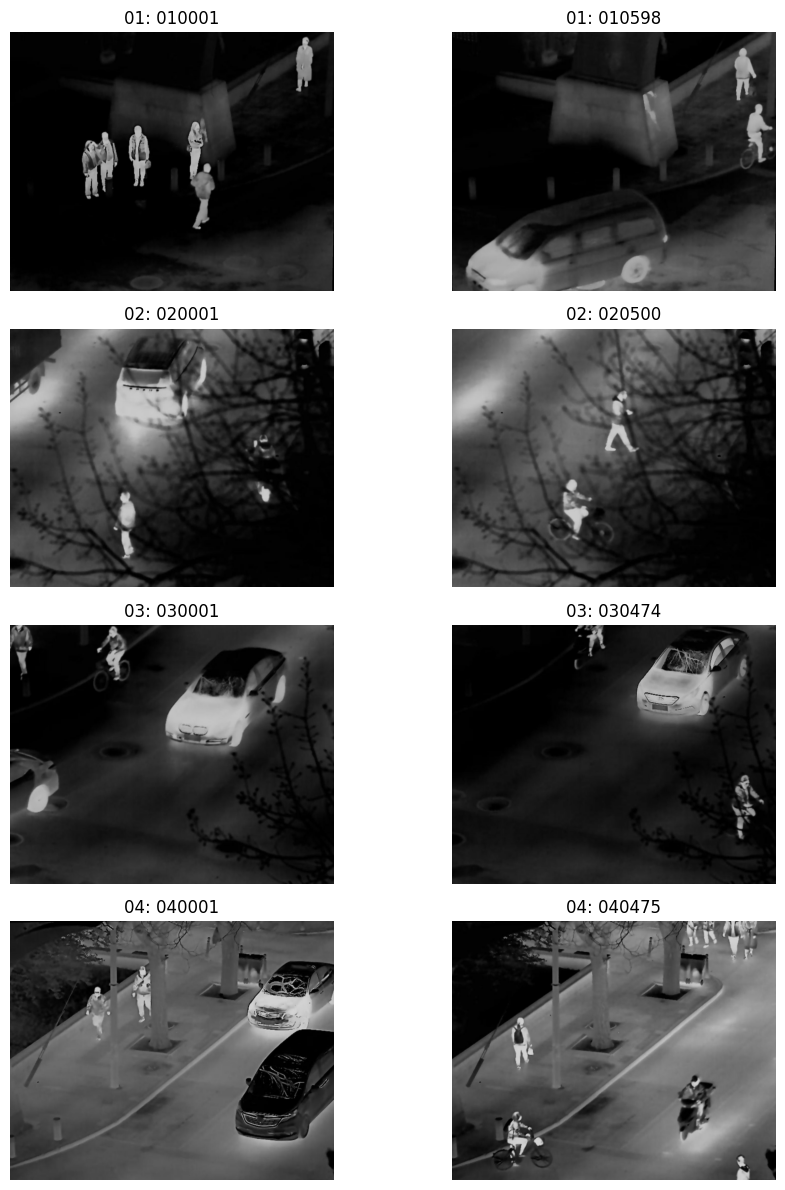

In [9]:
groups = Counter(p[:2] for p in pairs)
print(len(groups), "prefixes:", sorted(groups.items()))

import matplotlib.pyplot as plt
check = sorted(groups)[:4]   # look at a few prefixes
fig, axes = plt.subplots(len(check), 2, figsize=(10, 3 * len(check)))
for row, g in zip(axes, check):
    ids = sorted(p for p in pairs if p[:2] == g)
    for ax, p in zip(row, [ids[0], ids[-1]]):
        ax.imshow(Image.open(ir[p])); ax.set_title(f"{g}: {p}"); ax.axis("off")
plt.tight_layout(); plt.show()

Cell 10: Make and save the split

In [10]:
GROUPING_RELIABLE = True   # set from what you saw in Cell 9
SEED, VAL_FRAC = 42, 0.15
rng = random.Random(SEED)
target = VAL_FRAC * len(pairs)

if GROUPING_RELIABLE:
    gids = sorted(groups); rng.shuffle(gids)
    val_groups, n = [], 0
    for g in gids:   # add whole groups while it moves the count closer to 15%
        if abs(n + groups[g] - target) < abs(n - target):
            val_groups.append(g); n += groups[g]
    val_ids = sorted(p for p in pairs if p[:2] in val_groups)
    method = f"group split by ID prefix (first 2 digits); val groups: {sorted(val_groups)}"
else:
    shuffled = pairs[:]; rng.shuffle(shuffled)
    val_ids = sorted(shuffled[:round(target)])
    method = "random pair-level split (scene grouping not established)"

train_ids = sorted(set(pairs) - set(val_ids))
assert not set(train_ids) & set(val_ids)

DATA = "/content/eo_ir_data"
os.makedirs(f"{DATA}/manifests", exist_ok=True)
open(f"{DATA}/manifests/train_ids.txt", "w").write("\n".join(train_ids) + "\n")
open(f"{DATA}/manifests/val_ids.txt", "w").write("\n".join(val_ids) + "\n")
split_info = {"seed": SEED, "val_fraction_target": VAL_FRAC, "method": method,
              "train_pairs": len(train_ids), "val_pairs": len(val_ids),
              "overlap": len(set(train_ids) & set(val_ids))}
json.dump(split_info, open(f"{DATA}/manifests/split_info.json", "w"), indent=2)
print(json.dumps(split_info, indent=2))

{
  "seed": 42,
  "val_fraction_target": 0.15,
  "method": "group split by ID prefix (first 2 digits); val groups: ['05', '14', '15', '18']",
  "train_pairs": 10030,
  "val_pairs": 1995,
  "overlap": 0
}


Cell 11: Some Annotated Overlay

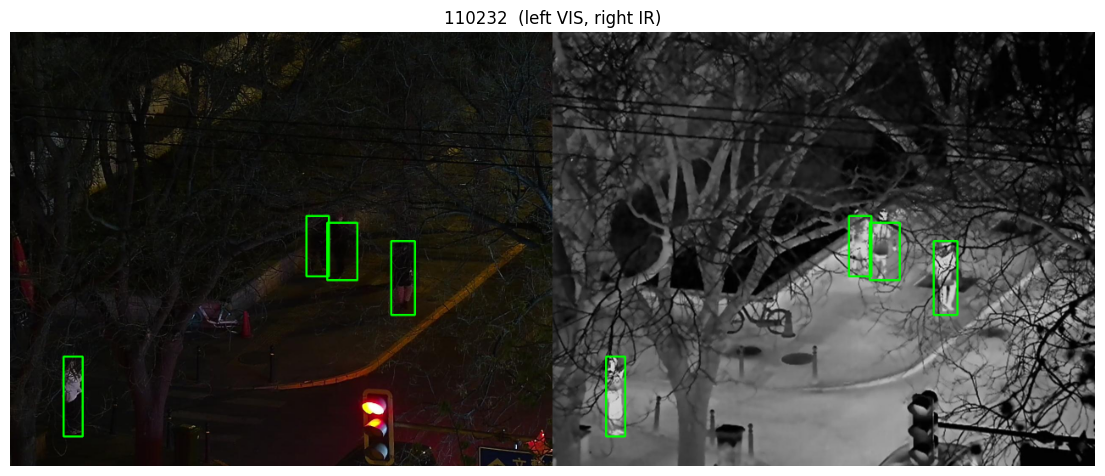

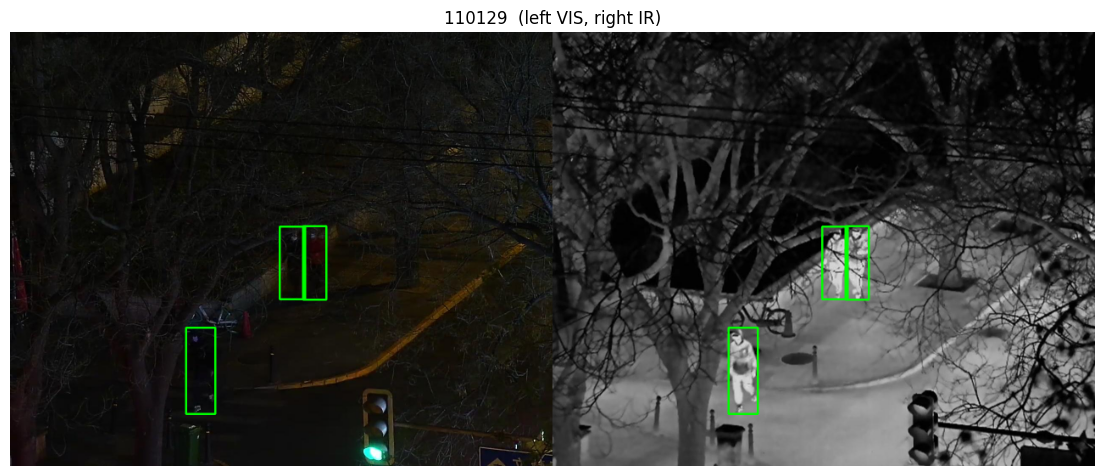

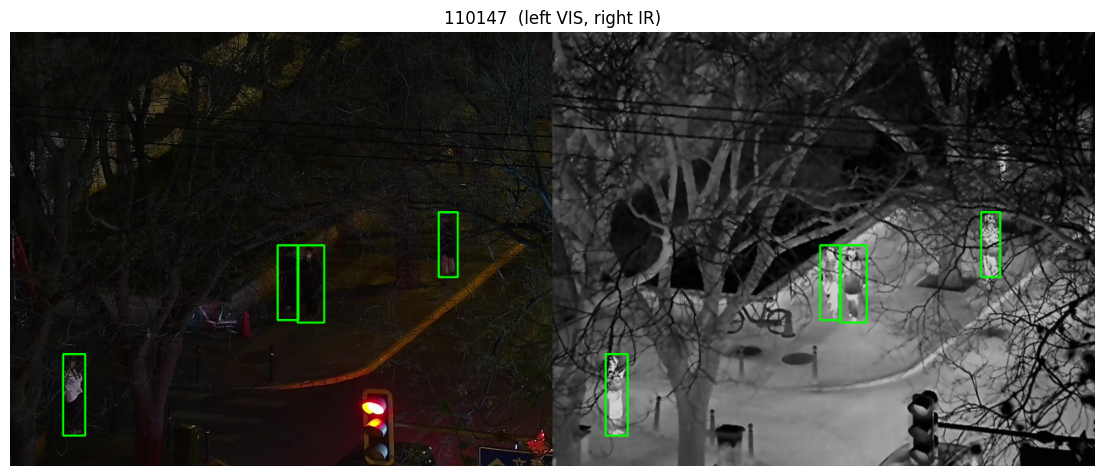

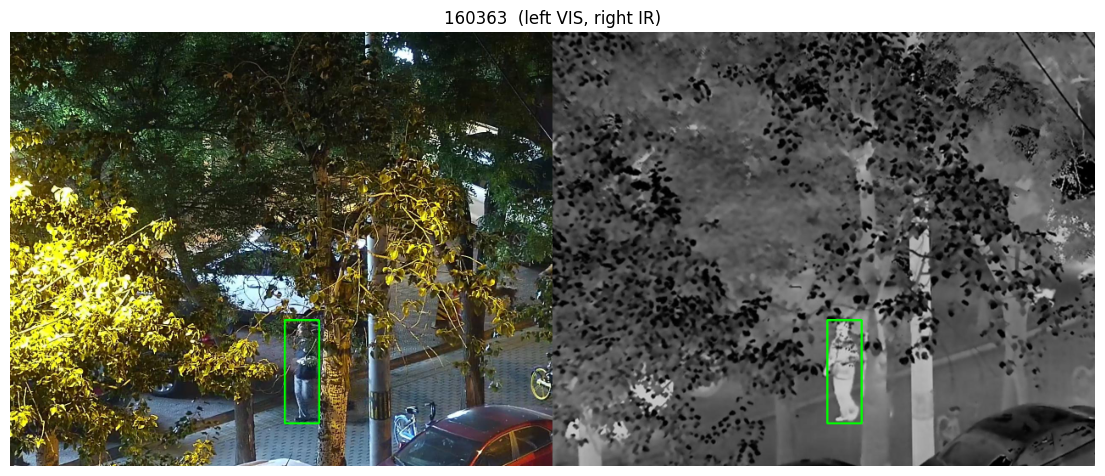

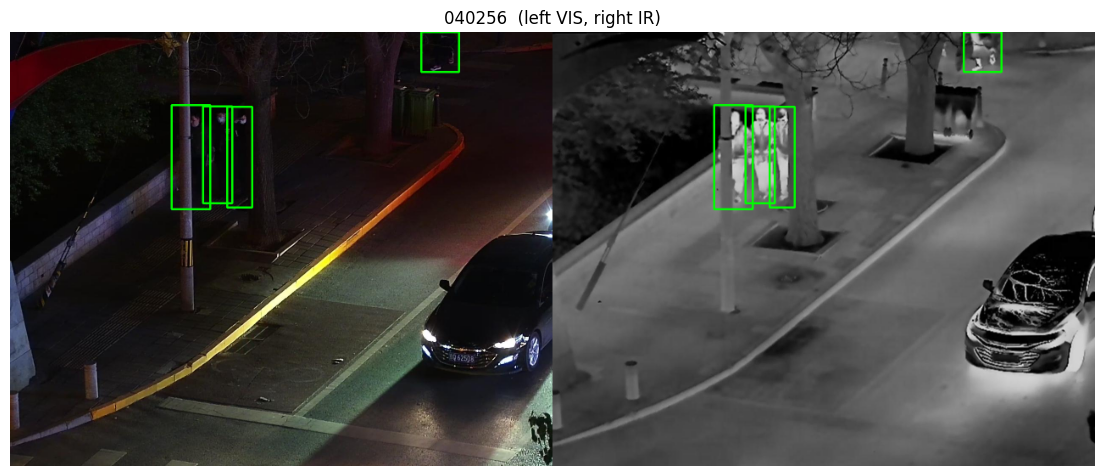

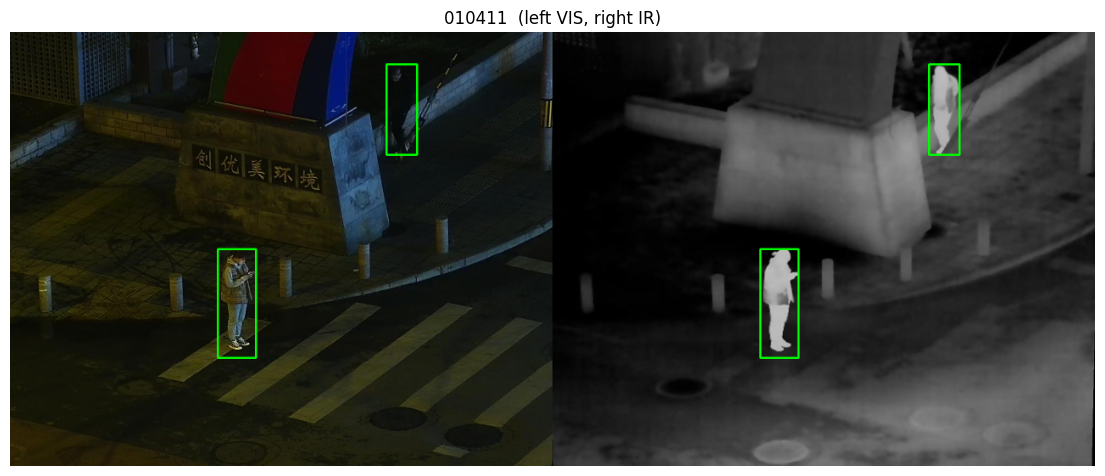

saved: ['110232', '110129', '110147', '160363', '040256', '010411']


In [11]:
import cv2, numpy as np
EVID = f"{DRIVE_ROOT}/evidence/annotation_overlays"
os.makedirs(EVID, exist_ok=True)

def draw(img_path, lbl_path):
    im = cv2.imread(img_path); H, W = im.shape[:2]
    for line in open(lbl_path).read().splitlines():
        if not line.strip(): continue
        _, cx, cy, w, h = map(float, line.split())
        cv2.rectangle(im, (int((cx-w/2)*W), int((cy-h/2)*H)), (int((cx+w/2)*W), int((cy+h/2)*H)), (0, 255, 0), 3)
    return im

sample = random.Random(SEED).sample(pairs, 400)
bright = {p: np.asarray(Image.open(vis[p]).convert("L")).mean() for p in sample}
darkest = sorted(bright, key=bright.get)[:3]                                  # dark VIS examples
by_group = {}
for p in sample: by_group.setdefault(p[:2], p)
varied = [p for p in by_group.values() if p not in darkest][:3]               # different scenes
chosen = darkest + varied

for p in chosen:
    lbl = f"{LABELS_TMP}/{p}.txt"
    pair_img = np.hstack([draw(vis[p], lbl), draw(ir[p], lbl)])
    pair_img = cv2.resize(pair_img, None, fx=0.5, fy=0.5)
    cv2.imwrite(f"{EVID}/{p}_vis_ir.jpg", pair_img)
    plt.figure(figsize=(14, 6)); plt.imshow(pair_img[:, :, ::-1])
    plt.title(f"{p}  (left VIS, right IR)"); plt.axis("off"); plt.show()
print("saved:", chosen)

Cell 12: Assemble the folder, YOLO image lists and inventory

In [12]:
for m, idx in [("vis", vis), ("ir", ir)]:
    os.makedirs(f"{DATA}/{m}/images", exist_ok=True)
    os.makedirs(f"{DATA}/{m}/labels", exist_ok=True)
    for p in pairs:
        name = os.path.basename(idx[p])
        shutil.copy2(idx[p], f"{DATA}/{m}/images/{name}")
        shutil.copy2(f"{LABELS_TMP}/{p}.txt", f"{DATA}/{m}/labels/{p}.txt")   # same labels for both
    for split, ids in [("train", train_ids), ("val", val_ids)]:
        with open(f"{DATA}/{m}_{split}.txt", "w") as f:
            f.writelines(f"./{m}/images/{os.path.basename(idx[p])}\n" for p in ids)

inventory["split"] = split_info
inventory["source_archive"] = ARCHIVE_NAME
json.dump(inventory, open(f"{DATA}/inventory.json", "w"), indent=2)
print(sorted(os.listdir(DATA)))

['inventory.json', 'ir', 'ir_train.txt', 'ir_val.txt', 'manifests', 'vis', 'vis_train.txt', 'vis_val.txt']


Cell 13: Zip, checksum, and save to Drive

In [13]:
!cd /content && zip -0 -r -q llvip_milestone.zip eo_ir_data
!cd /content && sha256sum llvip_milestone.zip | tee llvip_milestone.sha256
!cp /content/llvip_milestone.zip /content/llvip_milestone.sha256 /content/eo_ir_data/inventory.json "{PREP_DIR}/"
print(os.listdir(PREP_DIR))

729ef02b825dc03374801f8c3d6a1e5549b7cb414a954b40dd677c7971403a35  llvip_milestone.zip
['llvip_milestone.zip', 'llvip_milestone.sha256', 'inventory.json']
